In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv("cleaned_data/students.csv", dtype={"student_id": "string"})
grades = pd.read_csv("cleaned_data/term_grades.csv", dtype={"student_id": "string"})
sessions = pd.read_csv("cleaned_data/tutoring_sessions.csv.gz", dtype={"student_id": "string"})
courses = pd.read_csv("cleaned_data/courses.csv")

grades["failed"] = (
    (grades["term_grade"] == "F") | (pd.to_numeric(grades["term_grade"], errors="coerce") < 60)
)
attended = sessions.loc[sessions["attendance"] == "Present", "student_id"].unique()
students["tutored"] = students["student_id"].isin(attended)
students["gpa_group"] = pd.cut(
    students["prior_year_gpa"],
    bins=[-0.01, 1, 2, 3, 4.01],
    labels=["0-1", "1-2", "2-3", "3-4"]
)

analysis = grades.merge(
    students[["student_id", "tutored", "gpa_group", "grade_level"]],
    on="student_id", how="left"
).merge(
    courses[["course_code", "subject_area"]],
    on="course_code", how="left"
)

attended_subjects = sessions.loc[
    sessions["attendance"] == "Present", ["student_id", "subject_area"]
].drop_duplicates().assign(tutored_subject=True)
analysis = analysis.merge(
    attended_subjects,
    on=["student_id", "subject_area"], how="left"
)
analysis["tutored_subject"] = analysis["tutored_subject"].fillna(False)


C:\Users\Kings\AppData\Local\Temp\ipykernel_9200\3791933400.py:42: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  analysis["tutored_subject"] = analysis["tutored_subject"].fillna(False).astype(bool)


## Are the tutored students failing because they have a lower GPA?

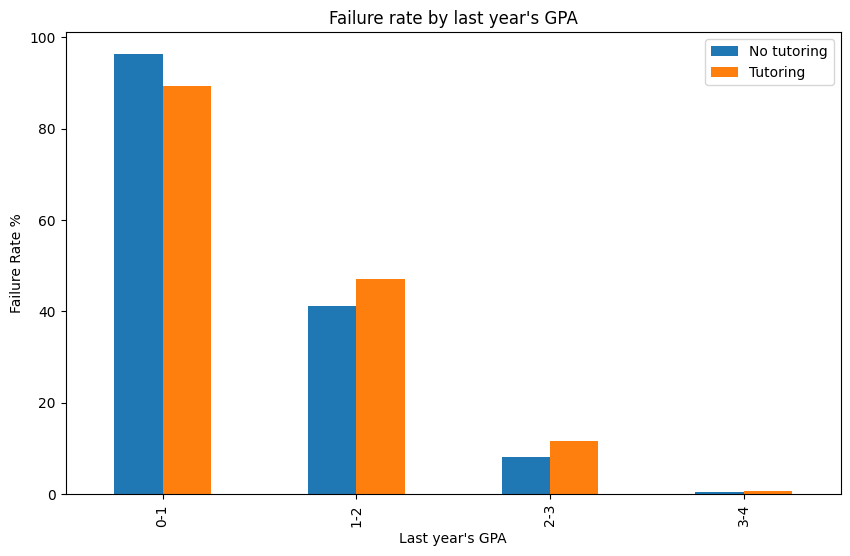

In [13]:
failure_rates = (
    analysis.groupby(["gpa_group", "tutored"], observed=True)["failed"]
    .mean().mul(100).unstack()
)
failure_rates.plot(kind="bar", figsize=(10, 6))
plt.title("Failure rate by last year's GPA")
plt.xlabel("Last year's GPA")
plt.ylabel("Failure Rate %")
plt.legend(["No tutoring", "Tutoring"])


## Does the grade of the student affect whether or not they fail?

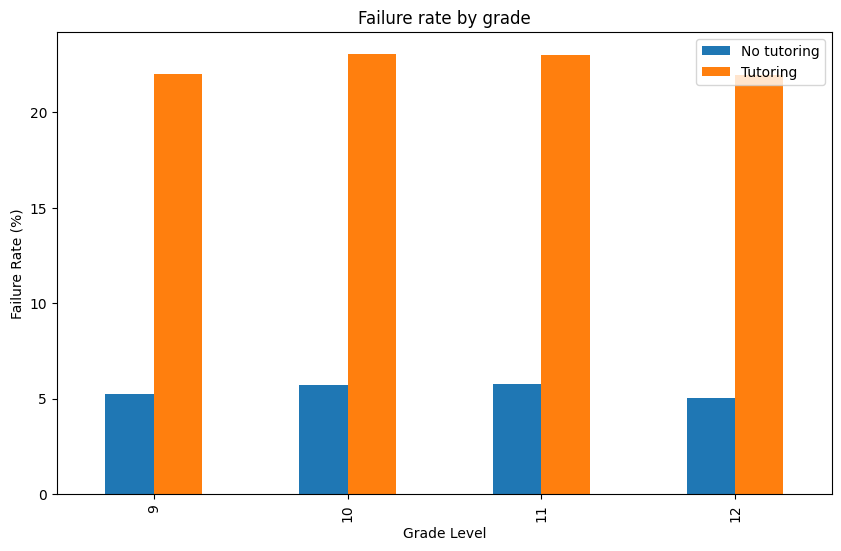

In [12]:
grade_rates = (
    analysis.groupby(["grade_level", "tutored"])["failed"]
    .mean().mul(100).unstack()
)
grade_rates.plot(kind="bar", figsize=(10, 6))
plt.title("Failure rate by grade")
plt.xlabel("Grade Level")
plt.ylabel("Failure Rate (%)")
plt.legend(["No tutoring", "Tutoring"])


## Are the students receiving tutoring in the right subject?

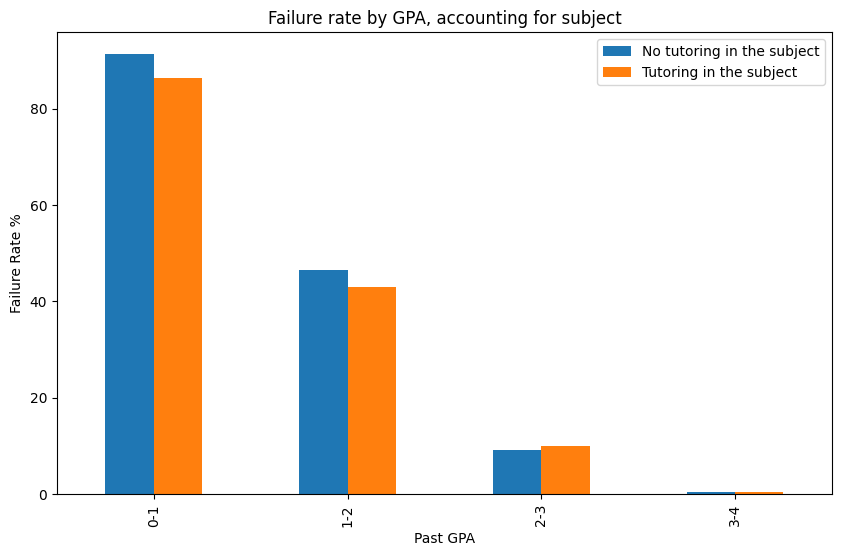

In [11]:
subject_rates = (
    analysis.groupby(["gpa_group", "tutored_subject"], observed=True)["failed"]
    .mean().mul(100).unstack()
)
subject_rates.plot(kind="bar", figsize=(10, 6))
plt.title("Failure rate by GPA, accounting for subject")
plt.xlabel("Past GPA")
plt.ylabel("Failure Rate %")
plt.legend(["No tutoring in the subject", "Tutoring in the subject"])


## It seems that the GPA of the student receiving tutoring is important to whether or not they fail.